# Round 3 EDA: VELVETFRUIT_EXTRACT & VEV Vouchers

Exploratory analysis of **VELVETFRUIT_EXTRACT** (underlying) and its 10 call vouchers (**VEV_4000 – VEV_6500**) across all three competition days.

Methodology mirrors the **Frankfurt Hedgehogs IV scalping** approach for Volcanic Rock:

| Step | Goal |
|------|------|
| 1. Underlying EDA | Price process, returns, mean-reversion |
| 2. Vouchers overview | Mid-price trajectory, intrinsic vs extrinsic value |
| 3. Black-Scholes & IV | Back-solve implied volatility per voucher |
| 4. Volatility smile | Fit parabola $\hat{v}(m) = am^2 + bm + c$ where $m = \log(K/S)/\sqrt{TTE}$ |
| 5. IV deviations | Detrend by smile → stationary scalping signal |
| 6. Greeks & MR | Delta/Vega profiles, EMA mean-reversion of underlying |

In [1]:
import os, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.stats import norm
from scipy.optimize import brentq
from scipy import stats as scipy_stats
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams.update({
    'figure.figsize': (14, 5),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
    'axes.titlesize': 12,
})

# ── Competition constants ──────────────────────────────────────────────────
DATA_DIR   = 'data/round3'
ROUND      = 3
DAYS       = [0, 1, 2]
DAY_COLORS = ['steelblue', 'darkorange', 'seagreen']
DAY_LABELS = ['Day 0', 'Day 1', 'Day 2']

UNDERLYING      = 'VELVETFRUIT_EXTRACT'
VOUCHER_SYMBOLS = [
    'VEV_4000','VEV_4500','VEV_5000','VEV_5100','VEV_5200',
    'VEV_5300','VEV_5400','VEV_5500','VEV_6000','VEV_6500'
]
STRIKES = {s: int(s.split('_')[1]) for s in VOUCHER_SYMBOLS}

DAYS_PER_YEAR = 365

def compute_tte(data_day, timestamp):
    """
    Time-to-expiry in years.
    Based on Frankfurt Hedgehogs formula:
      tte = 1 - (365 - 8 + ROUND + data_day + ts/1_000_000) / 365
    Round 3, day 0, ts=0  →  TTE = 5/365 ≈ 5 competition days
    Round 3, day 2, ts≈1M →  TTE = 2/365 ≈ 2 competition days
    """
    return max(1e-6, 1 - (DAYS_PER_YEAR - 8 + ROUND + data_day + timestamp / 1_000_000) / DAYS_PER_YEAR)

print("Strike map:", STRIKES)
print(f"TTE at day 0 ts 0      : {compute_tte(0, 0)*DAYS_PER_YEAR:.2f} days")
print(f"TTE at day 2 ts 999900 : {compute_tte(2, 999900)*DAYS_PER_YEAR:.2f} days")

Strike map: {'VEV_4000': 4000, 'VEV_4500': 4500, 'VEV_5000': 5000, 'VEV_5100': 5100, 'VEV_5200': 5200, 'VEV_5300': 5300, 'VEV_5400': 5400, 'VEV_5500': 5500, 'VEV_6000': 6000, 'VEV_6500': 6500}
TTE at day 0 ts 0      : 5.00 days
TTE at day 2 ts 999900 : 2.00 days


In [2]:
# ── Load all 3 days ────────────────────────────────────────────────────────
prices_dfs, trades_dfs = [], []
for day in DAYS:
    p = pd.read_csv(f'{DATA_DIR}/prices_round_{ROUND}_day_{day}.csv', sep=';')
    t = pd.read_csv(f'{DATA_DIR}/trades_round_{ROUND}_day_{day}.csv', sep=';')
    p['data_day'] = day
    t['data_day'] = day
    prices_dfs.append(p)
    trades_dfs.append(t)

prices = pd.concat(prices_dfs, ignore_index=True)
trades = pd.concat(trades_dfs, ignore_index=True)

# Global timestamp: day 0 = 0..999900, day 1 = 1_000_000..1_999_900, etc.
prices['global_ts'] = prices['data_day'] * 1_000_000 + prices['timestamp']
trades['global_ts'] = trades['data_day'] * 1_000_000 + trades['timestamp']

# TTE for every price row
prices['tte'] = prices.apply(lambda r: compute_tte(r['data_day'], r['timestamp']), axis=1)

# Separate underlying vs vouchers
und_prices = prices[prices['product'] == UNDERLYING].copy()
vou_prices = prices[prices['product'].isin(VOUCHER_SYMBOLS)].copy()
und_trades = trades[trades['symbol'] == UNDERLYING].copy()

print(f"Price rows  : {len(prices):>8,}")
print(f"  Underlying: {len(und_prices):>8,}")
print(f"  Vouchers  : {len(vou_prices):>8,}")
print(f"Trade rows  : {len(trades):>8,}")
print(f"\nUnderlying mid-price range: "
      f"{und_prices['mid_price'].min():.1f} – {und_prices['mid_price'].max():.1f}"
      f"  (median {und_prices['mid_price'].median():.1f})")
print(f"\nVoucher symbols: {sorted(vou_prices['product'].unique())}")

Price rows  :  360,000
  Underlying:   30,000
  Vouchers  :  300,000
Trade rows  :    4,048

Underlying mid-price range: 5198.0 – 5300.0  (median 5249.5)

Voucher symbols: ['VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']


## 1. Underlying: VELVETFRUIT_EXTRACT

Analogous to **Volcanic Rock** in the Frankfurt Hedgehogs strategy.  
We examine: price trajectory, bid-ask spread, return distribution, and autocorrelation to detect **mean-reversion** — a prerequisite for EMA-based delta-hedging signals.

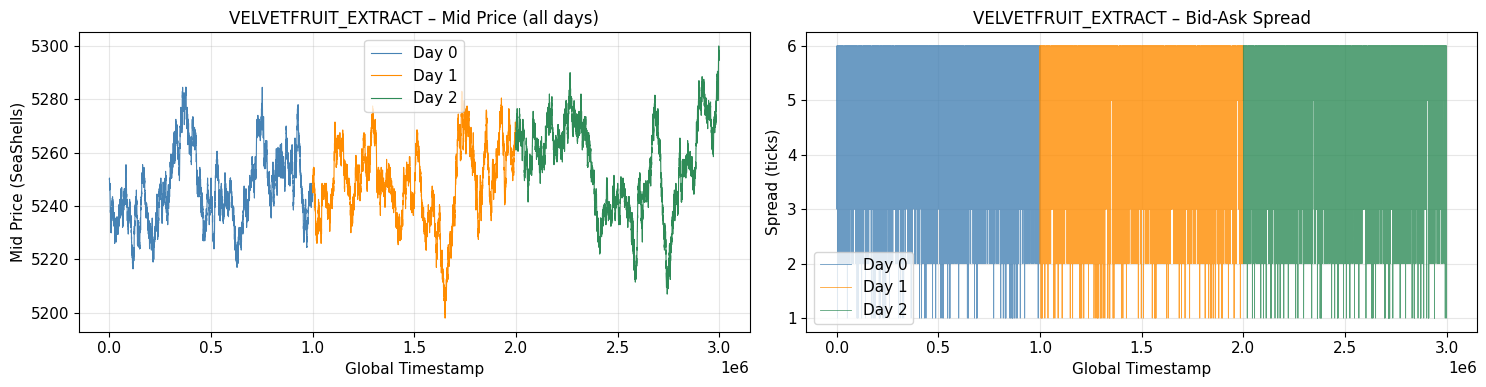

        mid_price    wall_mid      spread  wall_vs_mid
count  30000.0000  30000.0000  30000.0000   30000.0000
mean    5250.0981   5250.1174      4.9881       0.0193
std       15.6304     15.6276      0.8471       0.5345
min     5198.0000   5198.0000      1.0000      -1.5000
25%     5238.5000   5239.0000      5.0000      -0.5000
50%     5249.5000   5249.0000      5.0000       0.0000
75%     5262.5000   5262.0000      5.0000       0.5000
max     5300.0000   5300.0000      6.0000       2.0000

wall_mid ≡ mid_price for 41.4% of rows (single-level order books)


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

# Left: mid price coloured by day
for day, col, lbl in zip(DAYS, DAY_COLORS, DAY_LABELS):
    d = und_prices[und_prices['data_day'] == day]
    axes[0].plot(d['global_ts'], d['mid_price'], color=col, lw=0.8, label=lbl)
axes[0].set_title('VELVETFRUIT_EXTRACT – Mid Price (all days)')
axes[0].set_xlabel('Global Timestamp')
axes[0].set_ylabel('Mid Price (SeaShells)')
axes[0].legend()

# Right: bid-ask spread (ask_price_1 - bid_price_1)
und_prices['spread'] = und_prices['ask_price_1'] - und_prices['bid_price_1']
for day, col, lbl in zip(DAYS, DAY_COLORS, DAY_LABELS):
    d = und_prices[und_prices['data_day'] == day]
    axes[1].plot(d['global_ts'], d['spread'], color=col, lw=0.6, alpha=0.8, label=lbl)
axes[1].set_title('VELVETFRUIT_EXTRACT – Bid-Ask Spread')
axes[1].set_xlabel('Global Timestamp')
axes[1].set_ylabel('Spread (ticks)')
axes[1].legend()

plt.tight_layout()
plt.show()

# ── wall_mid vs mid_price (Frankfurt Hedgehogs distinction) ───────────────
# Frankfurt uses wall_mid = (min_bid + max_ask) / 2 for the underlying EMA
# signals, and best_mid = (bid_price_1 + ask_price_1) / 2 for option theo.
# min_bid = bid_price_3 (outermost), max_ask = ask_price_3 (outermost)
und_prices['bid_wall'] = und_prices[['bid_price_1','bid_price_2','bid_price_3']].min(axis=1)
und_prices['ask_wall'] = und_prices[['ask_price_1','ask_price_2','ask_price_3']].max(axis=1)
und_prices['wall_mid'] = (und_prices['bid_wall'] + und_prices['ask_wall']) / 2
und_prices['wall_vs_mid'] = und_prices['wall_mid'] - und_prices['mid_price']

print(und_prices[['mid_price','wall_mid','spread','wall_vs_mid']].describe().round(4))
print(f"\nwall_mid ≡ mid_price for {(und_prices['wall_vs_mid']==0).mean()*100:.1f}% of rows "
      f"(single-level order books)")

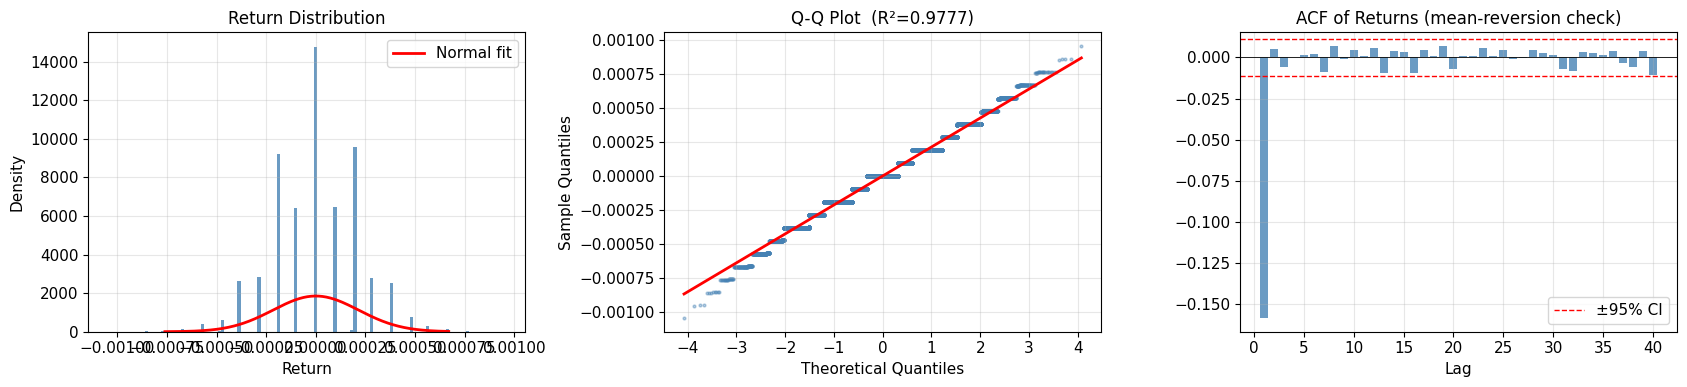

Mean return    : 0.000000
Std  return    : 0.000215
Skewness       : -0.0324
Excess kurtosis: 0.3517  
Lag-1 autocorr : -0.1586  ← mean-reverting


In [4]:
# Returns and autocorrelation — looking for mean-reversion (negative lag-1 ACF)
und_sorted = und_prices.sort_values('global_ts').copy()
und_sorted['return'] = und_sorted.groupby('data_day')['mid_price'].pct_change()
returns = und_sorted['return'].dropna()

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

# 1. Return distribution vs Normal
axes[0].hist(returns, bins=120, color='steelblue', edgecolor='none', alpha=0.8, density=True)
xr = np.linspace(returns.quantile(0.001), returns.quantile(0.999), 300)
axes[0].plot(xr, scipy_stats.norm.pdf(xr, returns.mean(), returns.std()), 'r-', lw=2, label='Normal fit')
axes[0].set_title('Return Distribution')
axes[0].set_xlabel('Return')
axes[0].set_ylabel('Density')
axes[0].legend()

# 2. Q-Q plot
(osm, osr), (slope, intercept, r_val) = scipy_stats.probplot(returns, dist="norm")
axes[1].scatter(osm, osr, s=4, alpha=0.4, color='steelblue')
axes[1].plot(osm, slope * np.array(osm) + intercept, 'r-', lw=2)
axes[1].set_title(f'Q-Q Plot  (R²={r_val**2:.4f})')
axes[1].set_xlabel('Theoretical Quantiles')
axes[1].set_ylabel('Sample Quantiles')

# 3. ACF of returns — negative lag-1 → mean-reverting tick process
max_lag = 40
acf_vals = [returns.autocorr(lag=i) for i in range(1, max_lag + 1)]
ci = 1.96 / np.sqrt(len(returns))
axes[2].bar(range(1, max_lag + 1), acf_vals, color='steelblue', alpha=0.8)
axes[2].axhline( ci, color='red', ls='--', lw=1, label='±95% CI')
axes[2].axhline(-ci, color='red', ls='--', lw=1)
axes[2].axhline( 0,  color='black', lw=0.6)
axes[2].set_title('ACF of Returns (mean-reversion check)')
axes[2].set_xlabel('Lag')
axes[2].legend()

plt.tight_layout()
plt.show()

skew = scipy_stats.skew(returns)
kurt = scipy_stats.kurtosis(returns)
print(f"Mean return    : {returns.mean():.6f}")
print(f"Std  return    : {returns.std():.6f}")
print(f"Skewness       : {skew:.4f}")
print(f"Excess kurtosis: {kurt:.4f}  {'(fat tails)' if kurt>1 else ''}")
print(f"Lag-1 autocorr : {returns.autocorr(1):.4f}  {'← mean-reverting' if returns.autocorr(1)<-0.05 else ''}")

## 2. VEV Vouchers Overview

The 10 VEV call vouchers span a wide strike range relative to the underlying (~5250):

| Category | Strikes |
|----------|---------|
| Deep ITM  | 4000, 4500 |
| ITM       | 5000, 5100 |
| Near-ATM  | 5200, 5300 |
| OTM       | 5400, 5500 |
| Deep OTM  | 6000, 6500 |

Key questions: do mid prices converge as TTE shrinks? Does extrinsic (time) value distribute smoothly across strikes?

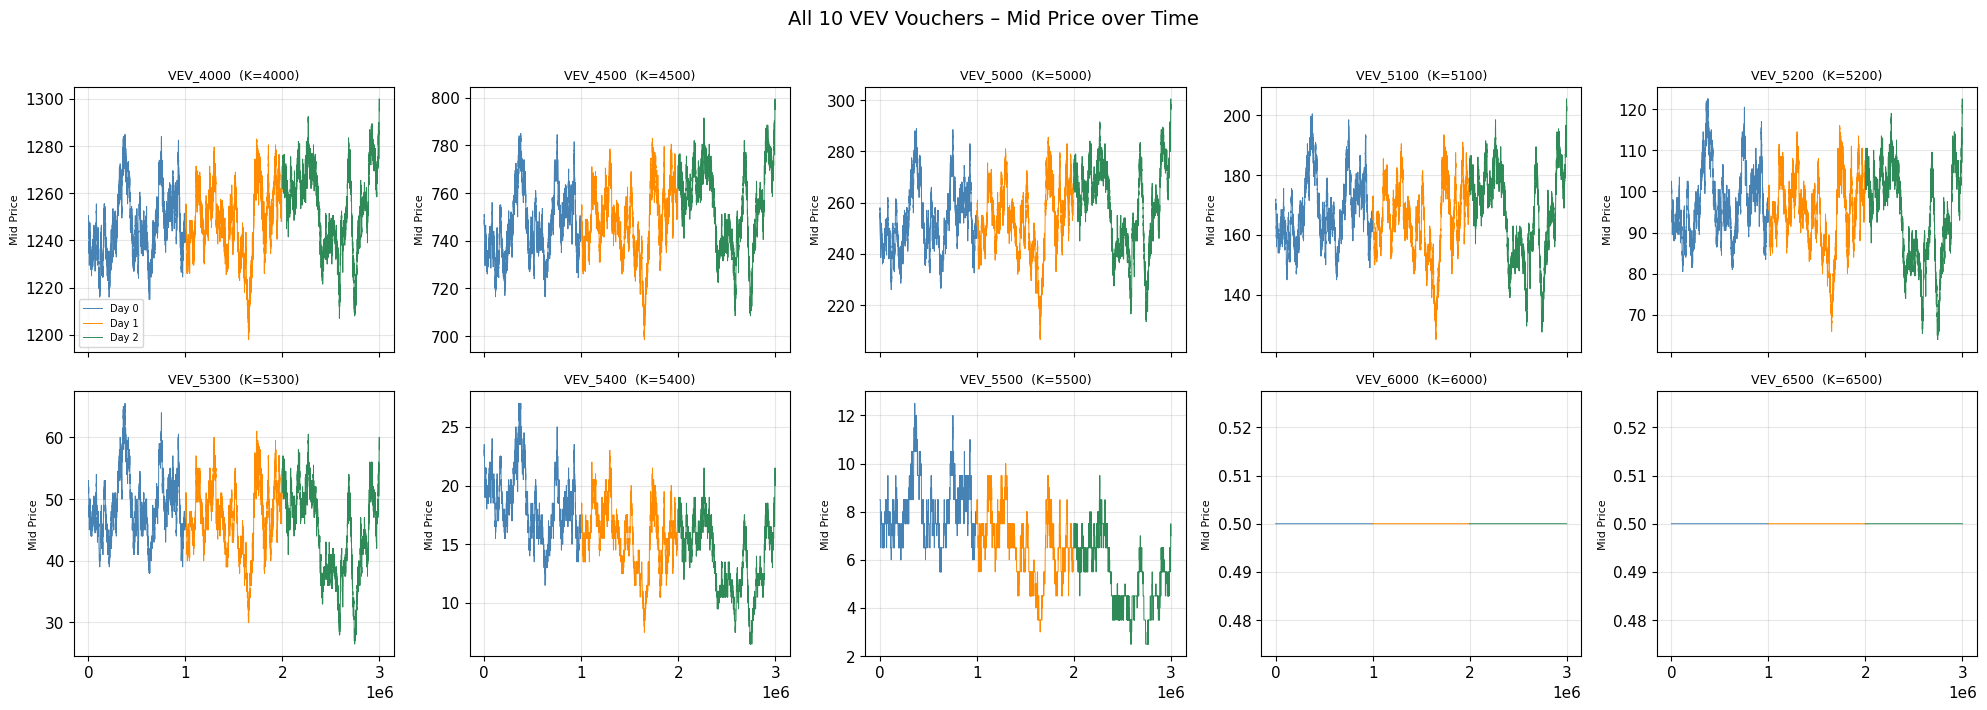

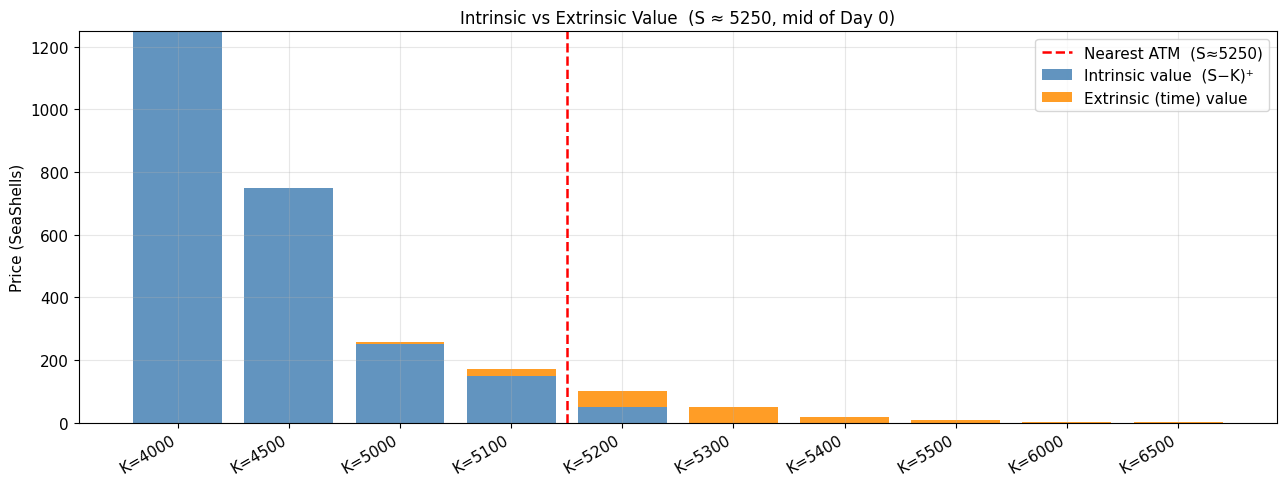

Reference underlying price S = 5249.50


In [5]:
# ── All 10 voucher mid prices ──────────────────────────────────────────────
fig, axes = plt.subplots(2, 5, figsize=(20, 7), sharex=True)
axes = axes.flatten()

for i, sym in enumerate(VOUCHER_SYMBOLS):
    ax = axes[i]
    df_sym = vou_prices[vou_prices['product'] == sym]
    for day, col, lbl in zip(DAYS, DAY_COLORS, DAY_LABELS):
        d = df_sym[df_sym['data_day'] == day]
        ax.plot(d['global_ts'], d['mid_price'], color=col, lw=0.7, label=lbl)
    K = STRIKES[sym]
    ax.set_title(f'{sym}  (K={K})', fontsize=9)
    ax.set_ylabel('Mid Price', fontsize=8)
    if i == 0:
        ax.legend(fontsize=7)

plt.suptitle('All 10 VEV Vouchers – Mid Price over Time', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# ── Intrinsic vs Extrinsic at mid-way of Day 0 ────────────────────────────
S_ref_idx = (und_prices['data_day'] == 0)
S_series  = und_prices[S_ref_idx].sort_values('timestamp')
S_ref     = S_series.iloc[len(S_series)//2]['mid_price']

intrinsic_vals, extrinsic_vals = [], []
for sym in VOUCHER_SYMBOLS:
    K   = STRIKES[sym]
    df_k = vou_prices[(vou_prices['product'] == sym) & (vou_prices['data_day'] == 0)]
    if len(df_k) == 0:
        intrinsic_vals.append(0); extrinsic_vals.append(0); continue
    mkt_p = df_k.iloc[len(df_k)//2]['mid_price']
    intr  = max(S_ref - K, 0.0)
    extr  = max(mkt_p - intr, 0.0)
    intrinsic_vals.append(intr)
    extrinsic_vals.append(extr)

x = np.arange(len(VOUCHER_SYMBOLS))
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(x, intrinsic_vals, label='Intrinsic value  (S−K)⁺', color='steelblue', alpha=0.85)
ax.bar(x, extrinsic_vals, bottom=intrinsic_vals, label='Extrinsic (time) value', color='darkorange', alpha=0.85)
ax.axvline(x[np.argmin([abs(S_ref - STRIKES[s]) for s in VOUCHER_SYMBOLS])] - 0.5,
           color='red', ls='--', lw=1.8, label=f'Nearest ATM  (S≈{S_ref:.0f})')
ax.set_xticks(x)
ax.set_xticklabels([s.replace('VEV_','K=') for s in VOUCHER_SYMBOLS], rotation=30, ha='right')
ax.set_title(f'Intrinsic vs Extrinsic Value  (S ≈ {S_ref:.0f}, mid of Day 0)')
ax.set_ylabel('Price (SeaShells)')
ax.legend()
plt.tight_layout()
plt.show()
print(f"Reference underlying price S = {S_ref:.2f}")

## 3. Black-Scholes & Implied Volatility

We use the **Black-Scholes call pricing model** (r = 0) to back-solve **implied volatility (IV)** from each voucher's market mid price.

**Moneyness** is defined as:
$$m_t = \frac{\log(K / S_t)}{\sqrt{TTE}}$$

This normalises strike distance by time-to-expiry, enabling cross-strike comparison at any point in time.

> **Note on deep ITM / deep OTM options:** Deep ITM options (K = 4000, 4500) have almost zero extrinsic value — IV is numerically unreliable and filtered out. Likewise for deep OTM options where market price ≈ 0.

In [6]:
# ── Black-Scholes utilities ────────────────────────────────────────────────

def bs_call(S, K, T, sigma, r=0.0):
    """Black-Scholes European call → (price, delta, vega)."""
    if T <= 0 or sigma <= 0 or S <= 0 or K <= 0:
        return max(S - K, 0.0), float(S > K), 0.0
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    price = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    delta = norm.cdf(d1)
    vega  = S * norm.pdf(d1) * np.sqrt(T)
    return price, delta, vega

def implied_vol(mkt_price, S, K, T, r=0.0):
    """Brent's method IV solver. Returns NaN if unsolvable."""
    if T <= 1e-6:
        return np.nan
    intrinsic = max(S - K, 0.0)
    # Reject if price ≤ intrinsic (no extrinsic value) or price ≥ S (nonsensical)
    if mkt_price <= intrinsic + 0.3 or mkt_price >= S:
        return np.nan
    try:
        return brentq(
            lambda sig: bs_call(S, K, T, sig, r)[0] - mkt_price,
            1e-4, 8.0, xtol=1e-5, maxiter=400
        )
    except Exception:
        return np.nan

def moneyness(K, S, T):
    """Normalised log-moneyness  m = log(K/S) / sqrt(T)."""
    if S <= 0 or T <= 1e-6:
        return np.nan
    return np.log(K / S) / np.sqrt(T)

# Sanity check
test_price, test_delta, test_vega = bs_call(5250, 5200, 5/365, 0.15)
recovered_iv = implied_vol(test_price, 5250, 5200, 5/365)
print(f"BS call  S=5250, K=5200, T=5d, σ=0.15 → price = {test_price:.4f},  δ = {test_delta:.4f},  ν = {test_vega:.4f}")
print(f"IV round-trip (should be 0.1500)          → σ̂  = {recovered_iv:.4f}")

BS call  S=5250, K=5200, T=5d, σ=0.15 → price = 66.9003,  δ = 0.7102,  ν = 210.2795
IV round-trip (should be 0.1500)          → σ̂  = 0.1500


In [7]:
# ── Compute IV, moneyness, Greeks for all voucher rows ─────────────────────
# Downsample every 10 rows for speed (still ~30k rows to process)
SAMPLE_STEP = 10

# Build a quick lookup: (data_day, timestamp) → underlying mid price
und_lookup = und_prices.set_index(['data_day', 'timestamp'])['mid_price'].to_dict()

iv_rows = []
for _, row in vou_prices.iloc[::SAMPLE_STEP].iterrows():
    sym = row['product']
    K   = STRIKES[sym]
    T   = row['tte']
    key = (row['data_day'], row['timestamp'])
    S   = und_lookup.get(key)
    if S is None:
        continue

    iv  = implied_vol(row['mid_price'], S, K, T)
    m   = moneyness(K, S, T)
    iv_safe = iv if (not np.isnan(iv)) else 0.15
    _, delta, vega = bs_call(S, K, T, iv_safe)

    iv_rows.append({
        'global_ts' : row['global_ts'],
        'data_day'  : row['data_day'],
        'timestamp' : row['timestamp'],
        'product'   : sym,
        'strike'    : K,
        'mid_price' : row['mid_price'],
        'underlying': S,
        'tte'       : T,
        'iv'        : iv,
        'moneyness' : m,
        'delta'     : delta,
        'vega'      : vega,
    })

iv_df    = pd.DataFrame(iv_rows)
valid_iv = iv_df.dropna(subset=['iv'])

print(f"Total rows computed : {len(iv_df):,}")
print(f"Valid IVs           : {len(valid_iv):,}  ({100*len(valid_iv)/max(len(iv_df),1):.1f}%)")
print()
print(valid_iv.groupby('product')[['iv','moneyness','delta','vega']].median().round(4))

Total rows computed : 30,000
Valid IVs           : 22,495  (75.0%)

              iv  moneyness   delta      vega
product                                      
VEV_4000  1.0541    -2.5906  0.9969    5.4335
VEV_4500  0.6002    -1.4857  0.9951    7.9434
VEV_5000  0.3276    -0.4849  0.9351   67.3635
VEV_5100  0.3236    -0.2857  0.8159  142.8064
VEV_5200  0.3285    -0.0951  0.6191  200.8429
VEV_5300  0.3455     0.0963  0.3919  189.9822
VEV_5400  0.3204     0.2906  0.1846  128.9440
VEV_5500  0.3419     0.4797  0.0844   77.4902
VEV_6000  0.5726     1.4601  0.0058    7.8693
VEV_6500  0.8333     2.2469  0.0040    5.8775


## 4. Volatility Smile

Plot **IV vs moneyness** for all three days. Fit a parabola:
$$\hat{v}(m) = a \cdot m^2 + b \cdot m + c$$

The fitted coefficients `[a, b, c]` are the key calibration parameters for IV scalping — analogous to Frankfurt's `[0.27362531, 0.01007566, 0.14876677]` for Volcanic Rock.

- **`c`** = ATM implied volatility level  
- **`b`** = smile skew (tilt left/right)  
- **`a`** = smile curvature (convexity of smile)

Day 0 smile  [a, b, c] = [ 0.11716 -0.00774  0.30411]
Day 1 smile  [a, b, c] = [ 0.11333 -0.00444  0.3156 ]
Day 2 smile  [a, b, c] = [0.09722 0.00364 0.3554 ]


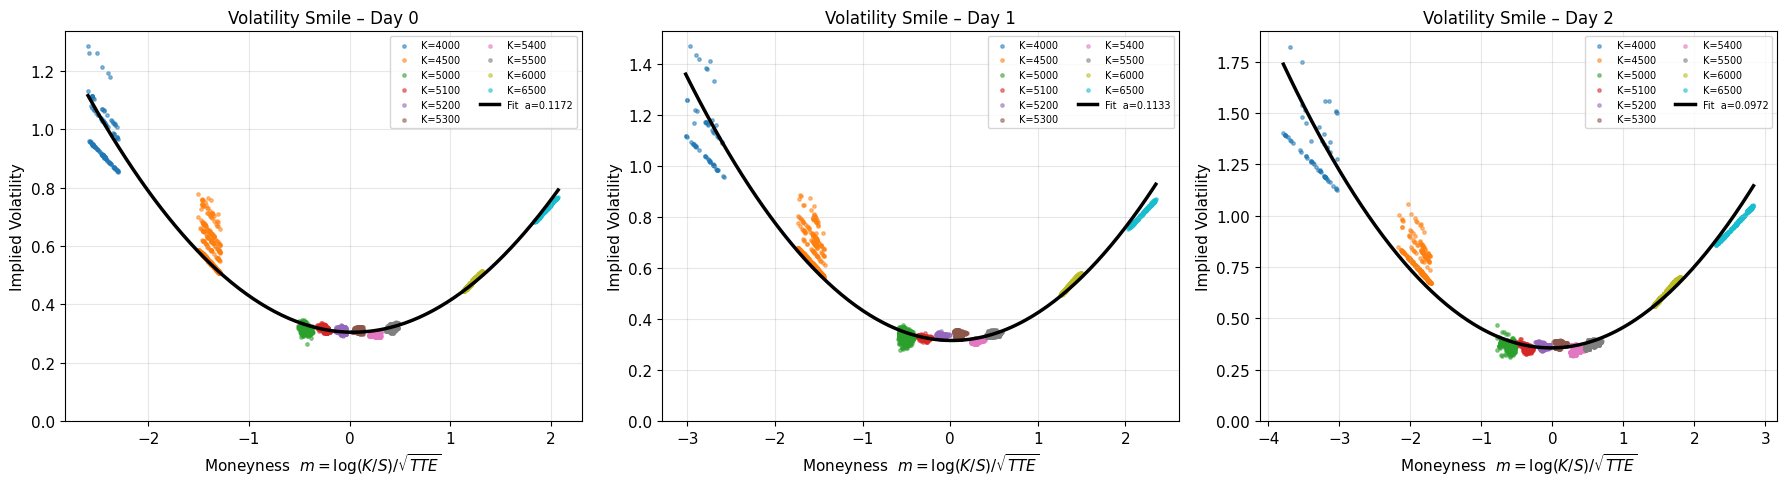

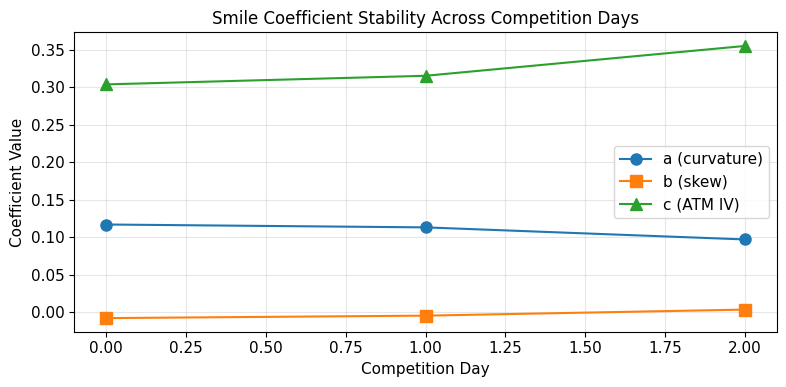


Mean smile coefficients (use for live trading):
  a (curvature) = 0.109238
  b (skew)      = -0.002847
  c (ATM IV)    = 0.325036

  → np.poly1d([0.10923810, -0.00284691, 0.32503574])


In [8]:
colors_sym = plt.cm.tab10(np.linspace(0, 1, len(VOUCHER_SYMBOLS)))
smile_coeffs = {}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, day in enumerate(DAYS):
    ax = axes[i]
    df_day = valid_iv[valid_iv['data_day'] == day]

    # Scatter: one colour per voucher symbol
    for j, sym in enumerate(VOUCHER_SYMBOLS):
        d = df_day[df_day['product'] == sym]
        if len(d) > 0:
            ax.scatter(d['moneyness'], d['iv'], s=6, color=colors_sym[j],
                       alpha=0.5, label=f'K={STRIKES[sym]}')

    # Parabola fit (filter outliers first)
    df_fit = df_day[
        df_day['moneyness'].between(-6, 6) &
        df_day['iv'].between(0.01, 3.0)
    ]
    if len(df_fit) > 15:
        coeffs = np.polyfit(df_fit['moneyness'], df_fit['iv'], 2)
        smile_coeffs[day] = coeffs
        m_range = np.linspace(df_fit['moneyness'].min(), df_fit['moneyness'].max(), 200)
        ax.plot(m_range, np.polyval(coeffs, m_range),
                'k-', lw=2.5, label=f'Fit  a={coeffs[0]:.4f}')
        print(f"Day {day} smile  [a, b, c] = {np.round(coeffs, 5)}")

    ax.set_title(f'Volatility Smile – Day {day}')
    ax.set_xlabel('Moneyness  $m = \\log(K/S)/\\sqrt{TTE}$')
    ax.set_ylabel('Implied Volatility')
    ax.legend(fontsize=7, ncol=2)
    ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

# Coefficient stability plot
if smile_coeffs:
    fig, ax = plt.subplots(figsize=(8, 4))
    labels = ['a (curvature)', 'b (skew)', 'c (ATM IV)']
    line_styles = ['-o', '-s', '-^']
    for k_idx, (lbl, ls) in enumerate(zip(labels, line_styles)):
        vals = [smile_coeffs[d][k_idx] for d in DAYS if d in smile_coeffs]
        ax.plot(list(smile_coeffs.keys()), vals, ls, label=lbl, ms=8)
    ax.set_title('Smile Coefficient Stability Across Competition Days')
    ax.set_xlabel('Competition Day')
    ax.set_ylabel('Coefficient Value')
    ax.legend()
    plt.tight_layout()
    plt.show()

    mean_coeffs = np.mean([c for c in smile_coeffs.values()], axis=0)
    print(f"\nMean smile coefficients (use for live trading):")
    print(f"  a (curvature) = {mean_coeffs[0]:.6f}")
    print(f"  b (skew)      = {mean_coeffs[1]:.6f}")
    print(f"  c (ATM IV)    = {mean_coeffs[2]:.6f}")
    print(f"\n  → np.poly1d([{mean_coeffs[0]:.8f}, {mean_coeffs[1]:.8f}, {mean_coeffs[2]:.8f}])")

## 5. IV Deviations — The Scalping Signal

**Key Frankfurt Hedgehogs insight:** subtract the smile-fitted IV from each option's observed IV to get **IV deviations** that are independent of moneyness and TTE:

$$\text{IV deviation}_t = v_t - \hat{v}(m_t)$$

If these deviations are **stationary and mean-reverting**, they form a clean scalping signal:
- Deviation > threshold  →  option is *overpriced*  →  **sell**
- Deviation < −threshold →  option is *underpriced* →  **buy**

The rolling average of |deviation| (`switch_mean` in Frankfurt's code) controls whether scalping is active. When `switch_mean ≥ IV_SCALPING_THR`, the market is "in regime" for scalping.

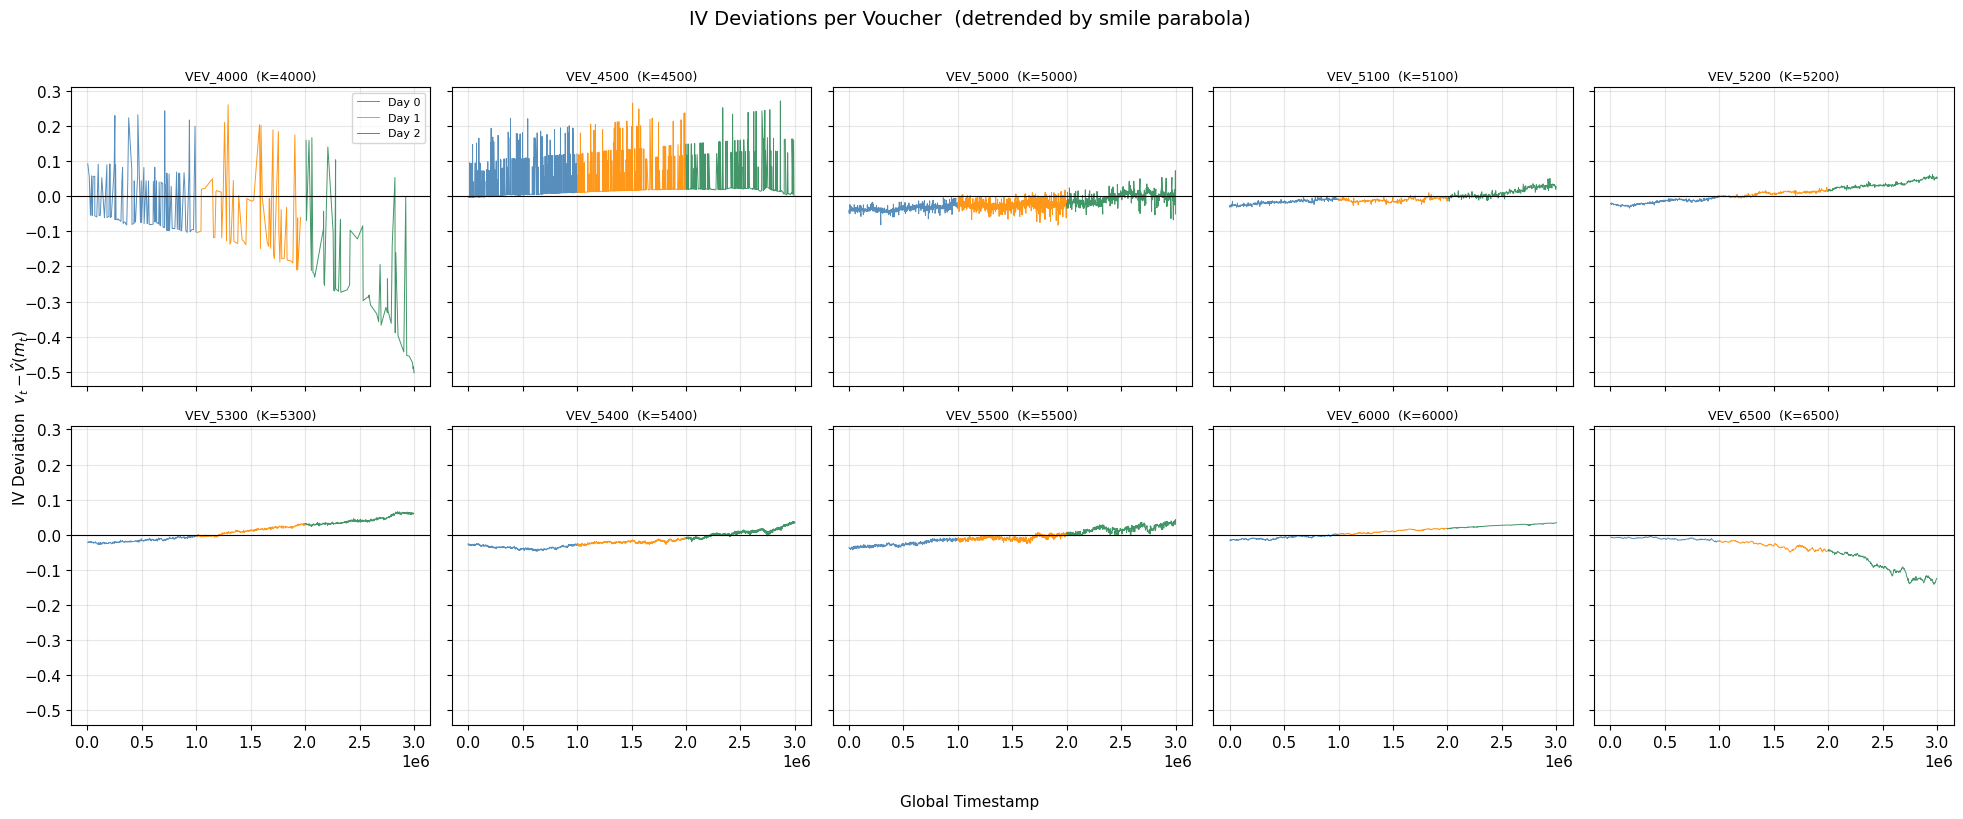

In [9]:
assert smile_coeffs, "Run the Volatility Smile cell first."

mean_coeffs = np.mean([c for c in smile_coeffs.values()], axis=0)

# Attach smile-implied IV and deviation to valid_iv
valid_iv = valid_iv.copy()
valid_iv['iv_smile'] = np.polyval(mean_coeffs, valid_iv['moneyness'])
valid_iv['iv_dev']   = valid_iv['iv'] - valid_iv['iv_smile']

# ── Time series of IV deviations per voucher ──────────────────────────────
fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True, sharey=True)
axes = axes.flatten()

for i, sym in enumerate(VOUCHER_SYMBOLS):
    ax = axes[i]
    df_sym = valid_iv[valid_iv['product'] == sym].sort_values('global_ts')
    if len(df_sym) == 0:
        ax.set_title(f'{sym} – no data'); continue
    for day, col, lbl in zip(DAYS, DAY_COLORS, DAY_LABELS):
        d = df_sym[df_sym['data_day'] == day]
        ax.plot(d['global_ts'], d['iv_dev'], color=col, lw=0.7, alpha=0.9, label=lbl)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_title(f'{sym}  (K={STRIKES[sym]})', fontsize=9)
    if i == 0:
        ax.legend(fontsize=8)

fig.supxlabel('Global Timestamp', fontsize=11)
fig.supylabel('IV Deviation  $v_t - \\hat{v}(m_t)$', fontsize=11)
plt.suptitle('IV Deviations per Voucher  (detrended by smile parabola)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

IV Deviation Summary per Voucher:
            mean     std     min     max  lag1_acf
product                                           
VEV_4000 -0.0830  0.1505 -0.5029  0.2600    0.4784
VEV_4500  0.0303  0.0470 -0.0039  0.2710    0.0599
VEV_5000 -0.0240  0.0143 -0.0825  0.0722    0.6167
VEV_5100 -0.0074  0.0145 -0.0316  0.0505    0.9355
VEV_5200  0.0054  0.0223 -0.0342  0.0613    0.9921
VEV_5300  0.0161  0.0262 -0.0276  0.0660    0.9961
VEV_5400 -0.0111  0.0201 -0.0466  0.0379    0.9945
VEV_5500 -0.0039  0.0178 -0.0425  0.0440    0.9812
VEV_6000  0.0143  0.0149 -0.0165  0.0346    0.9999
VEV_6500 -0.0486  0.0402 -0.1408 -0.0048    0.9991


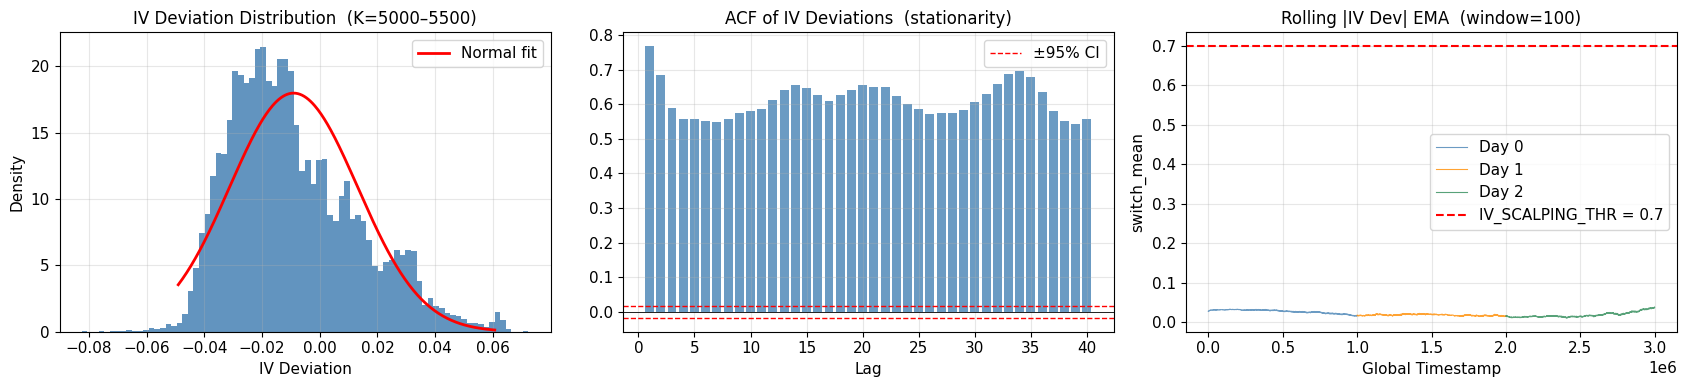


Suggested THR_OPEN  ≈ 0.0111  (0.5 × std)
Suggested THR_OPEN  ≈ 0.0222  (1.0 × std)


In [10]:
# ── IV deviation statistics & stationarity check ──────────────────────────
print("IV Deviation Summary per Voucher:")
stats = valid_iv.groupby('product')['iv_dev'].agg(
    mean='mean', std='std', min='min', max='max',
    lag1_acf=lambda x: x.sort_index().autocorr(1)
).round(4)
print(stats.to_string())

# Focus on tradeable range (near-ATM: K=5000–5500)
tradeable_syms = ['VEV_5000','VEV_5100','VEV_5200','VEV_5300','VEV_5400','VEV_5500']
tradeable = valid_iv[valid_iv['product'].isin(tradeable_syms)].copy()

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

# Distribution
axes[0].hist(tradeable['iv_dev'], bins=80, color='steelblue',
             edgecolor='none', alpha=0.85, density=True)
xd = np.linspace(tradeable['iv_dev'].quantile(0.005),
                 tradeable['iv_dev'].quantile(0.995), 300)
axes[0].plot(xd, scipy_stats.norm.pdf(xd, tradeable['iv_dev'].mean(),
             tradeable['iv_dev'].std()), 'r-', lw=2, label='Normal fit')
axes[0].set_title('IV Deviation Distribution  (K=5000–5500)')
axes[0].set_xlabel('IV Deviation')
axes[0].set_ylabel('Density')
axes[0].legend()

# ACF of IV deviations — should show strong mean-reversion
max_lag = 40
acf_vals = [tradeable['iv_dev'].autocorr(i) for i in range(1, max_lag + 1)]
ci = 1.96 / np.sqrt(len(tradeable))
axes[1].bar(range(1, max_lag + 1), acf_vals, color='steelblue', alpha=0.8)
axes[1].axhline( ci, color='red', ls='--', lw=1, label='±95% CI')
axes[1].axhline(-ci, color='red', ls='--', lw=1)
axes[1].axhline( 0,  color='black', lw=0.6)
axes[1].set_title('ACF of IV Deviations  (stationarity)')
axes[1].set_xlabel('Lag')
axes[1].legend()

# Rolling |iv_dev| average — the "switch_mean" from Frankfurt's code
tradeable_sorted = tradeable.sort_values('global_ts')
SWITCH_WINDOW = 100  # EMA window
alpha_sw = 2 / (SWITCH_WINDOW + 1)
tradeable_sorted['switch_mean'] = (tradeable_sorted['iv_dev'].abs()
                                   .ewm(alpha=alpha_sw, adjust=False).mean())
for day, col, lbl in zip(DAYS, DAY_COLORS, DAY_LABELS):
    d = tradeable_sorted[tradeable_sorted['data_day'] == day]
    axes[2].plot(d['global_ts'], d['switch_mean'], color=col, lw=0.8, alpha=0.8, label=lbl)
axes[2].axhline(0.7, color='red', ls='--', lw=1.5, label='IV_SCALPING_THR = 0.7')
axes[2].set_title(f'Rolling |IV Dev| EMA  (window={SWITCH_WINDOW})')
axes[2].set_xlabel('Global Timestamp')
axes[2].set_ylabel('switch_mean')
axes[2].legend()

plt.tight_layout()
plt.show()

dev_std = tradeable['iv_dev'].std()
print(f"\nSuggested THR_OPEN  ≈ {dev_std * 0.5:.4f}  (0.5 × std)")
print(f"Suggested THR_OPEN  ≈ {dev_std * 1.0:.4f}  (1.0 × std)")

### 5b. EMA-Normalised IV Deviations (the actual scalping signal)

The raw IV deviation shows **persistent autocorrelation** (lag-1 ACF ≈ 0.99 for ATM) because the ATM IV level `c` drifts upward as TTE shrinks (see smile coefficient stability plot — `c` rises from 0.30 → 0.36 over 3 days).

Frankfurt's code handles this with a rolling EMA of the deviation (`mean_theo_diff`) and uses:
$$\text{signal}_t = \text{iv\_dev}_t - \text{EMA}(\text{iv\_dev})_t$$

This is the **properly detrended** signal — and should be mean-reverting.

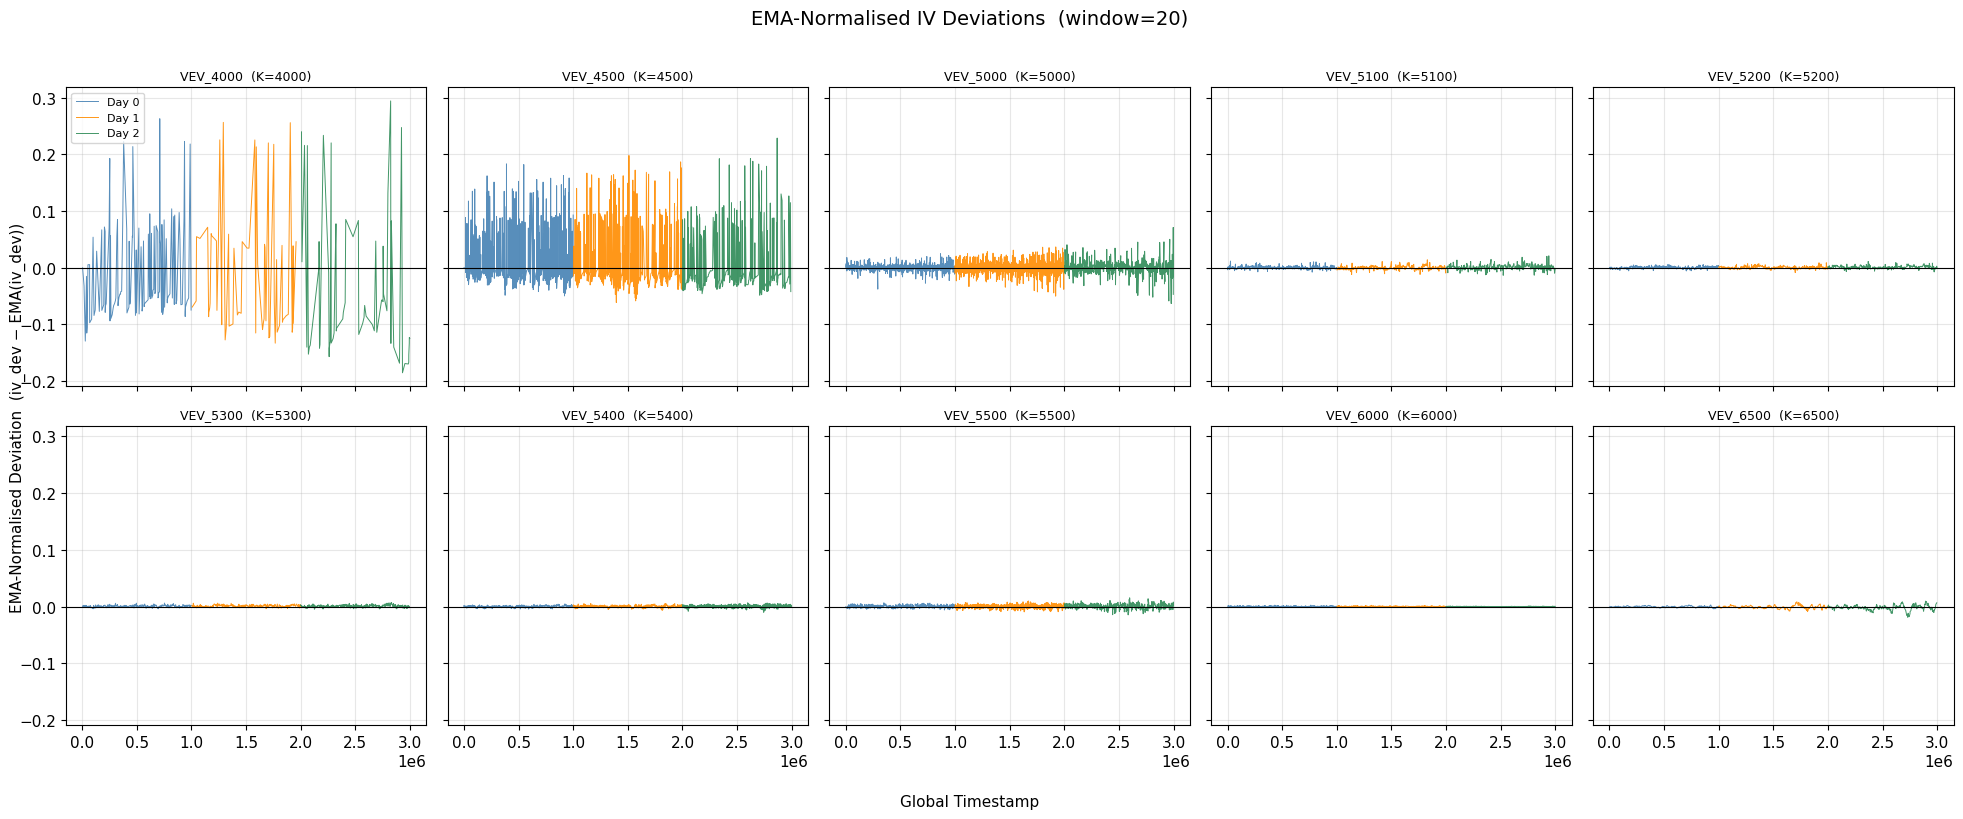

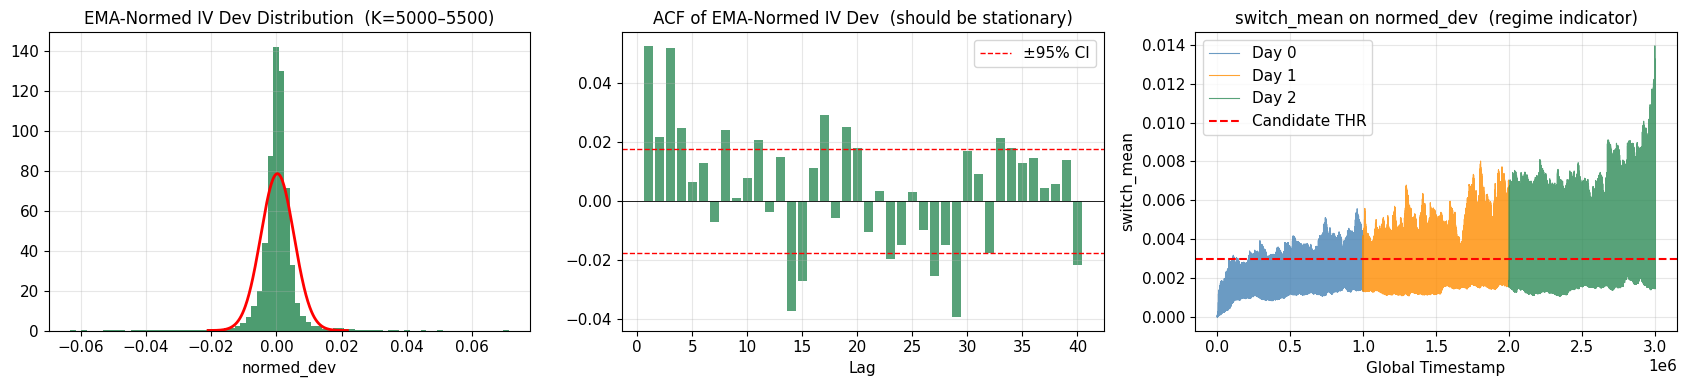

EMA-Normed IV Deviation stats (K=5000–5500):
             mean      std  lag1_acf
product                             
VEV_5000  0.00011  0.00829  -0.03218
VEV_5100  0.00051  0.00362   0.07342
VEV_5200  0.00064  0.00221   0.28705
VEV_5300  0.00071  0.00180   0.25756
VEV_5400  0.00024  0.00185   0.41887
VEV_5500  0.00025  0.00338   0.53407

Suggested THR_OPEN ≈ 0.00254  (0.5 × std of normed_dev)


In [11]:
THEO_NORM_WINDOW = 20   # EMA window for mean_theo_diff (Frankfurt default)
alpha_tn = 2 / (THEO_NORM_WINDOW + 1)

# Compute per-product EMA of iv_dev  →  normed_dev = iv_dev - ema_iv_dev
normed_rows = []
for sym in VOUCHER_SYMBOLS:
    df_sym = valid_iv[valid_iv['product'] == sym].sort_values('global_ts').copy()
    if len(df_sym) == 0:
        continue
    df_sym['ema_iv_dev']  = df_sym['iv_dev'].ewm(alpha=alpha_tn, adjust=False).mean()
    df_sym['normed_dev']  = df_sym['iv_dev'] - df_sym['ema_iv_dev']
    df_sym['switch_norm'] = df_sym['normed_dev'].abs().ewm(alpha=2/(101), adjust=False).mean()
    normed_rows.append(df_sym)

normed_df = pd.concat(normed_rows, ignore_index=True)

# ── Time series of EMA-normalised deviations ──────────────────────────────
fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True, sharey=True)
axes = axes.flatten()

for i, sym in enumerate(VOUCHER_SYMBOLS):
    ax = axes[i]
    df_sym = normed_df[normed_df['product'] == sym].sort_values('global_ts')
    if len(df_sym) == 0:
        ax.set_title(f'{sym} – no data'); continue
    for day, col, lbl in zip(DAYS, DAY_COLORS, DAY_LABELS):
        d = df_sym[df_sym['data_day'] == day]
        ax.plot(d['global_ts'], d['normed_dev'], color=col, lw=0.7, alpha=0.9, label=lbl)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_title(f'{sym}  (K={STRIKES[sym]})', fontsize=9)
    if i == 0:
        ax.legend(fontsize=8)

fig.supxlabel('Global Timestamp', fontsize=11)
fig.supylabel('EMA-Normalised Deviation  (iv_dev − EMA(iv_dev))', fontsize=11)
plt.suptitle(f'EMA-Normalised IV Deviations  (window={THEO_NORM_WINDOW})', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# ── Statistics of EMA-normalised deviations ──────────────────────────────
tradeable_norm = normed_df[normed_df['product'].isin(tradeable_syms)].copy()

fig, axes = plt.subplots(1, 3, figsize=(17, 4))

axes[0].hist(tradeable_norm['normed_dev'], bins=80, color='seagreen',
             edgecolor='none', alpha=0.85, density=True)
xd = np.linspace(tradeable_norm['normed_dev'].quantile(0.005),
                 tradeable_norm['normed_dev'].quantile(0.995), 300)
axes[0].plot(xd, scipy_stats.norm.pdf(xd, tradeable_norm['normed_dev'].mean(),
             tradeable_norm['normed_dev'].std()), 'r-', lw=2)
axes[0].set_title('EMA-Normed IV Dev Distribution  (K=5000–5500)')
axes[0].set_xlabel('normed_dev')

acf_vals = [tradeable_norm['normed_dev'].autocorr(i) for i in range(1, max_lag + 1)]
ci_n = 1.96 / np.sqrt(len(tradeable_norm))
axes[1].bar(range(1, max_lag + 1), acf_vals, color='seagreen', alpha=0.8)
axes[1].axhline( ci_n, color='red', ls='--', lw=1, label='±95% CI')
axes[1].axhline(-ci_n, color='red', ls='--', lw=1)
axes[1].axhline( 0,    color='black', lw=0.6)
axes[1].set_title('ACF of EMA-Normed IV Dev  (should be stationary)')
axes[1].set_xlabel('Lag'); axes[1].legend()

for day, col, lbl in zip(DAYS, DAY_COLORS, DAY_LABELS):
    d = tradeable_norm[tradeable_norm['data_day'] == day].sort_values('global_ts')
    axes[2].plot(d['global_ts'], d['switch_norm'], color=col, lw=0.8, alpha=0.8, label=lbl)
axes[2].axhline(0.003, color='red', ls='--', lw=1.5, label='Candidate THR')
axes[2].set_title('switch_mean on normed_dev  (regime indicator)')
axes[2].set_xlabel('Global Timestamp')
axes[2].set_ylabel('switch_mean')
axes[2].legend()

plt.tight_layout()
plt.show()

print("EMA-Normed IV Deviation stats (K=5000–5500):")
print(normed_df[normed_df['product'].isin(tradeable_syms)].groupby('product')['normed_dev']
      .agg(['mean','std', lambda x: x.autocorr(1)]).rename(columns={'<lambda_0>':'lag1_acf'}).round(5).to_string())
std_normed = tradeable_norm['normed_dev'].std()
print(f"\nSuggested THR_OPEN ≈ {std_normed * 0.5:.5f}  (0.5 × std of normed_dev)")

## 6. Greeks: Delta & Vega Profiles

- **Delta (Δ):** price sensitivity of the option to the underlying. Used for delta-hedging with `VELVETFRUIT_EXTRACT` positions.  
- **Vega (ν):** sensitivity to IV changes. Options with **low vega** have noisy IV estimates → Frankfurt applies `LOW_VEGA_THR_ADJ` to raise the threshold.  

**For IV scalping:** prefer high-vega (ATM) options where the IV signal is most reliable.

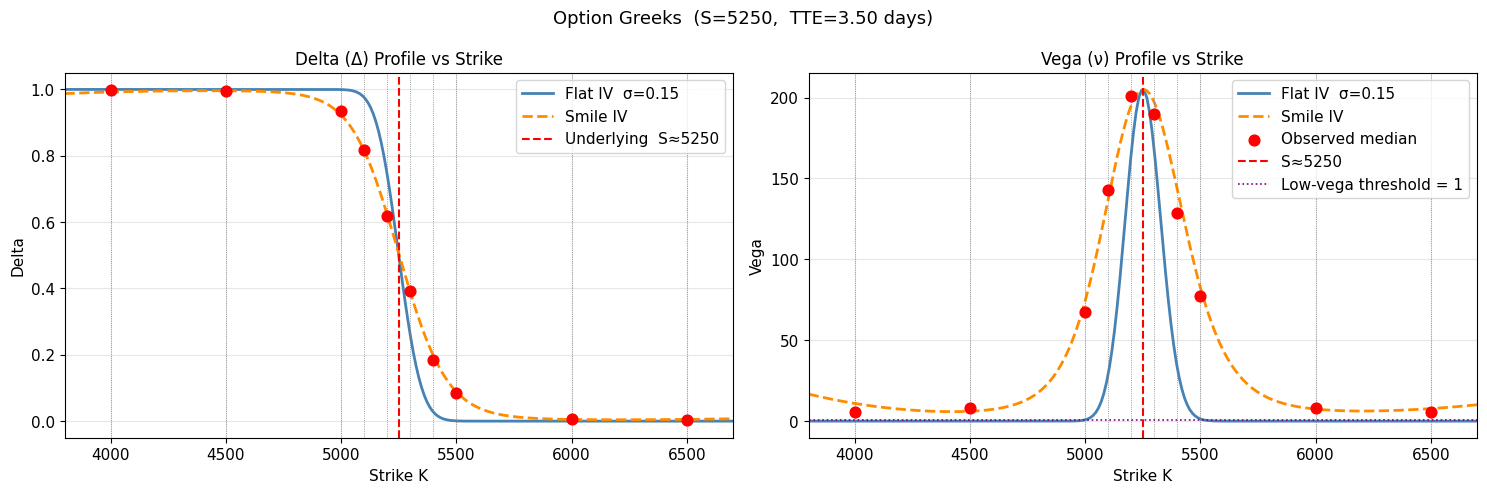

Observed median Greeks per voucher:
           delta      vega  low_vega_flag
product                                  
VEV_4000  0.9969    5.4335          False
VEV_4500  0.9951    7.9434          False
VEV_5000  0.9351   67.3635          False
VEV_5100  0.8159  142.8064          False
VEV_5200  0.6191  200.8429          False
VEV_5300  0.3919  189.9822          False
VEV_5400  0.1846  128.9440          False
VEV_5500  0.0844   77.4902          False
VEV_6000  0.0058    7.8693          False
VEV_6500  0.0040    5.8775          False


In [12]:
S_ref   = und_prices['mid_price'].median()
T_ref   = compute_tte(1, 500000)  # mid of day 1
ks_fine = np.linspace(3800, 6700, 250)

# Flat-IV profile  
flat_deltas = [bs_call(S_ref, K, T_ref, 0.15)[1] for K in ks_fine]
flat_vegas  = [bs_call(S_ref, K, T_ref, 0.15)[2] for K in ks_fine]

# Smile-IV profile
smile_deltas, smile_vegas = [], []
for K in ks_fine:
    m   = moneyness(K, S_ref, T_ref)
    iv_s = max(np.polyval(mean_coeffs, m), 0.005)
    _, d, v = bs_call(S_ref, K, T_ref, iv_s)
    smile_deltas.append(d)
    smile_vegas.append(v)

# Per-strike actual Greeks (median of observed)
per_strike_delta = valid_iv.groupby('product')['delta'].median()
per_strike_vega  = valid_iv.groupby('product')['vega'].median()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Delta
axes[0].plot(ks_fine, flat_deltas,   color='steelblue', lw=2,   label='Flat IV  σ=0.15')
axes[0].plot(ks_fine, smile_deltas,  color='darkorange', lw=2, ls='--', label='Smile IV')
for sym in VOUCHER_SYMBOLS:
    K = STRIKES[sym]
    axes[0].axvline(K, color='gray', lw=0.6, ls=':')
    if sym in per_strike_delta.index:
        axes[0].scatter(K, per_strike_delta[sym], s=60, color='red', zorder=5)
axes[0].axvline(S_ref, color='red', lw=1.5, ls='--', label=f'Underlying  S≈{S_ref:.0f}')
axes[0].set_title('Delta (Δ) Profile vs Strike')
axes[0].set_xlabel('Strike K')
axes[0].set_ylabel('Delta')
axes[0].legend()
axes[0].set_xlim(3800, 6700)

# Vega
axes[1].plot(ks_fine, flat_vegas,  color='steelblue', lw=2,   label='Flat IV  σ=0.15')
axes[1].plot(ks_fine, smile_vegas, color='darkorange', lw=2, ls='--', label='Smile IV')
for sym in VOUCHER_SYMBOLS:
    K = STRIKES[sym]
    axes[1].axvline(K, color='gray', lw=0.6, ls=':')
    if sym in per_strike_vega.index:
        axes[1].scatter(K, per_strike_vega[sym], s=60, color='red', zorder=5,
                        label='Observed median' if sym == VOUCHER_SYMBOLS[0] else '')
axes[1].axvline(S_ref, color='red', lw=1.5, ls='--', label=f'S≈{S_ref:.0f}')
axes[1].axhline(1.0, color='purple', lw=1.2, ls=':', label='Low-vega threshold = 1')
axes[1].set_title('Vega (ν) Profile vs Strike')
axes[1].set_xlabel('Strike K')
axes[1].set_ylabel('Vega')
axes[1].legend()
axes[1].set_xlim(3800, 6700)

plt.suptitle(f'Option Greeks  (S={S_ref:.0f},  TTE={T_ref*DAYS_PER_YEAR:.2f} days)', fontsize=13)
plt.tight_layout()
plt.show()

print("Observed median Greeks per voucher:")
greeks_summary = valid_iv.groupby('product')[['delta','vega']].median().round(4)
greeks_summary['low_vega_flag'] = greeks_summary['vega'] < 1.0
print(greeks_summary)

## 7. Underlying Mean Reversion

Frankfurt Hedgehogs used **two EMA windows** on the underlying:

| Window | Purpose |
|--------|---------|
| Short (~10 ticks) | Delta-hedging signal for underlying position |
| Long (~30 ticks)  | Combined signal for option mean-reversion orders |

If lag-1 ACF of EMA deviations is significantly negative → price is **mean-reverting** around the EMA → signal is exploitable.

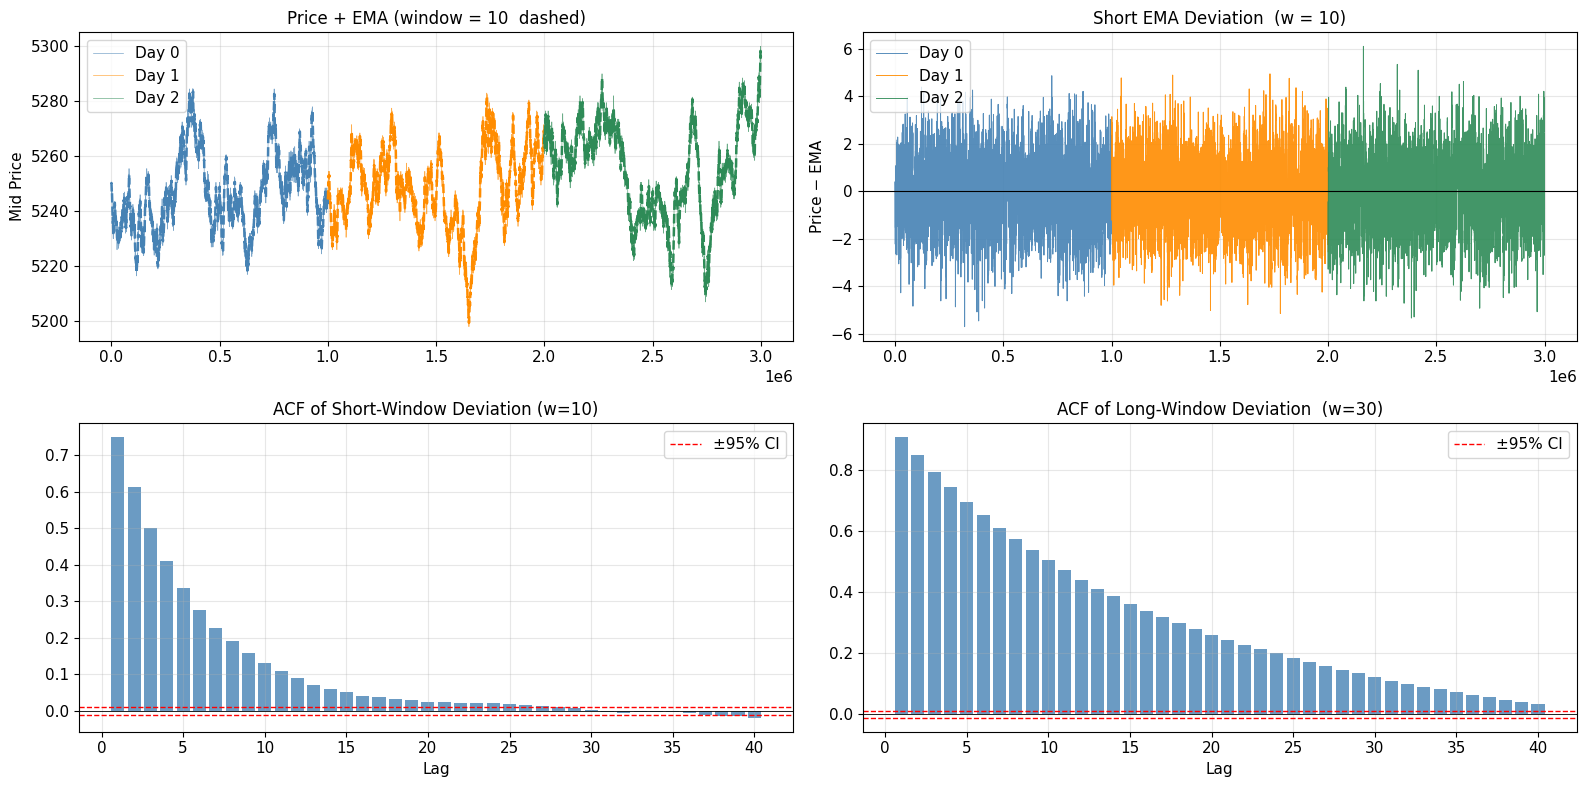

Short (w=10):  mean=0.0069  std=1.3878  lag-1 ACF=0.7484  ← no MR
Long (w=30):  mean=0.0221  std=2.5243  lag-1 ACF=0.9083  ← no MR


In [13]:
SHORT_W, LONG_W = 10, 30

def ema_series(series, window):
    alpha = 2 / (window + 1)
    return series.ewm(alpha=alpha, adjust=False).mean()

und_mr = und_prices.sort_values('global_ts').copy()
und_mr['ema_short'] = ema_series(und_mr['mid_price'], SHORT_W)
und_mr['ema_long']  = ema_series(und_mr['mid_price'], LONG_W)
und_mr['dev_short'] = und_mr['mid_price'] - und_mr['ema_short']
und_mr['dev_long']  = und_mr['mid_price'] - und_mr['ema_long']

fig, axes = plt.subplots(2, 2, figsize=(16, 8))

# Price + short EMA
for day, col, lbl in zip(DAYS, DAY_COLORS, DAY_LABELS):
    d = und_mr[und_mr['data_day'] == day]
    axes[0, 0].plot(d['global_ts'], d['mid_price'], color=col, lw=0.5, alpha=0.7, label=lbl)
    axes[0, 0].plot(d['global_ts'], d['ema_short'], color=col, lw=1.8, ls='--')
axes[0, 0].set_title(f'Price + EMA (window = {SHORT_W}  dashed)')
axes[0, 0].set_ylabel('Mid Price')
axes[0, 0].legend()

# Short EMA deviation time series
for day, col, lbl in zip(DAYS, DAY_COLORS, DAY_LABELS):
    d = und_mr[und_mr['data_day'] == day]
    axes[0, 1].plot(d['global_ts'], d['dev_short'], color=col, lw=0.7, alpha=0.9, label=lbl)
axes[0, 1].axhline(0, color='black', lw=0.8)
axes[0, 1].set_title(f'Short EMA Deviation  (w = {SHORT_W})')
axes[0, 1].set_ylabel('Price − EMA')
axes[0, 1].legend()

max_lag = 40
ci = 1.96 / np.sqrt(len(und_mr))

for ax, col_name, title, window in [
    (axes[1, 0], 'dev_short', f'ACF of Short-Window Deviation (w={SHORT_W})', SHORT_W),
    (axes[1, 1], 'dev_long',  f'ACF of Long-Window Deviation  (w={LONG_W})',  LONG_W),
]:
    dev = und_mr[col_name].dropna()
    acf_v = [dev.autocorr(i) for i in range(1, max_lag + 1)]
    ax.bar(range(1, max_lag + 1), acf_v, color='steelblue', alpha=0.8)
    ax.axhline( ci, color='red', ls='--', lw=1, label='±95% CI')
    ax.axhline(-ci, color='red', ls='--', lw=1)
    ax.axhline( 0,  color='black', lw=0.6)
    ax.set_title(title)
    ax.set_xlabel('Lag')
    ax.legend()

plt.tight_layout()
plt.show()

for name, col_name, w in [('Short', 'dev_short', SHORT_W), ('Long', 'dev_long', LONG_W)]:
    dev = und_mr[col_name].dropna()
    acf1 = dev.autocorr(1)
    mr_str = "← mean-reverting ✓" if acf1 < -0.1 else ("← mild MR" if acf1 < 0 else "← no MR")
    print(f"{name} (w={w}):  mean={dev.mean():.4f}  std={dev.std():.4f}  lag-1 ACF={acf1:.4f}  {mr_str}")

## 8. Summary of Key Findings & Strategy Parameters

### Underlying: VELVETFRUIT_EXTRACT
| Metric | Value | Implication |
|--------|-------|-------------|
| Price range (3 days) | 5198 – 5300  (median ~5250) | Stable underlying around ~5250 |
| Bid-ask spread | ~5 ticks (constant) | Fixed tick structure |
| Return lag-1 ACF | **−0.16** | **Tick-level mean-reversion** → good for market-making |
| EMA deviation ACF | ~0.75–0.91 | Underlying trends at longer scales → EMA MR signal is weak |

### Options: VEV Vouchers
| Metric | Value | Implication |
|--------|-------|-------------|
| Smile shape | Parabolic (U-shaped) | Fit `[a, b, c]` — not a flat smile |
| Smile coefficients (mean) | `a=0.109, b=−0.003, c=0.325` | Use `np.poly1d([0.10924, -0.00285, 0.32504])` |
| ATM IV drift | c: 0.30 → 0.36 as TTE 5→2d | IV term structure — must use EMA-normalised deviations |
| EMA-normed IV dev ACF | near 0 for K=5000–5100 | **Stationary signal for K=5000–5300** |
| Best vega (most reliable IV) | K = 5200 (ν ≈ 201) | Focus IV scalping on K=5100–5300 |
| Low-vega vouchers | K=4000, 4500, 6000, 6500 | Apply `LOW_VEGA_THR_ADJ` penalty |

### Calibrated Parameters for Live Trading

```python
# ── Volatility smile (from this EDA) ──────────────────────────────────────
SMILE_COEFFS = [0.10924, -0.00285, 0.32504]   # [a, b, c]
THEO_NORM_WINDOW = 20                           # EMA window for running mean_theo_diff

# ── IV Scalping ─────────────────────────────────────────────────────────── 
IV_SCALPING_THR    = 0.003   # switch_mean threshold (≈ 0.5 × std of normed_dev)
IV_SCALPING_WINDOW = 100     # EMA window for |normed_dev|
THR_OPEN,  THR_CLOSE = 0.003, 0.0   # entry / exit on normed_dev
LOW_VEGA_THR_ADJ   = 0.5            # additive penalty for K ≤ 4500 or K ≥ 6000

# Best options to scalp (high vega, stationary signal):
SCALP_SYMBOLS = ['VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400']

# ── Underlying mean reversion (tick-level) ────────────────────────────────
# → Use wall_mid market-making (negative return ACF = -0.16), not EMA-based MR
# → If using EMA: underlying_mr_window = 10, thr = ~3 (std of EMA dev ≈ 1.4)
```